# 08. Primary Achievement Embedding Generation & Artifact Persistence

Generates deterministic, L2-normalized 384-dimensional dense embeddings for all 1,540 records in achievement_dataset_v1.0.1, validates invariants, and saves versioned artifacts partitioned by dataset split.

**Dataset Release:** `achievement_dataset_v1.0.1` | **Author:** Member 1 (NLP & Semantic Intelligence Engineer)

## 1. Environment & Module Imports
We import our certified preprocessing and embedding utilities.

In [1]:
import os
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
import sys
import json
import time
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from nlp.text_preprocessing import prepare_text_for_sentence_transformer
from nlp.embedding import (
    load_embedding_model,
    generate_embeddings,
    validate_embeddings,
    save_embedding_bundle
)

print("Embedding generation pipeline initialized.")

Embedding generation pipeline initialized.


## 2. Load Frozen Dataset & Preprocess Text
We load the primary master dataset `data/processed/achievement_classification_dataset.csv` (1,540 records) and prepare natural language text for the transformer encoder.

In [2]:
data_path = REPO_ROOT / "data" / "processed" / "achievement_classification_dataset.csv"
df = pd.read_csv(data_path)
print(f"Loaded Master Dataset: {len(df)} records.")

# Apply sentence transformer text preparation (NFC + whitespace collapse, keeping casing/punctuation)
texts = [prepare_text_for_sentence_transformer(t) for t in df["achievement_text"]]
record_ids = df["achievement_id"].tolist()
categories = df["category"].tolist()

print(f"Prepared {len(texts)} texts for neural inference.")
print("Sample prepared text:", repr(texts[0][:100]))

Loaded Master Dataset: 1540 records.
Prepared 1540 texts for neural inference.
Sample prepared text: 'Co-inventor on patent application #2021553873 filed with the United States Patent and Trademark Offi'


## 3. Dense Embedding Inference via `all-MiniLM-L6-v2`
We load `all-MiniLM-L6-v2` and encode all 1,540 records with L2 normalization.

In [3]:
print("Loading model 'all-MiniLM-L6-v2' on CPU...")
model = load_embedding_model("all-MiniLM-L6-v2", device="cpu")

t0 = time.time()
embeddings = generate_embeddings(
    texts=texts,
    model=model,
    batch_size=32,
    normalize_embeddings=True,
    show_progress_bar=False
)
total_time = time.time() - t0
throughput = len(texts) / total_time

print(f"=== EMBEDDING GENERATION COMPLETE ===")
print(f"Total Records Encoded:  {len(embeddings)}")
print(f"Embedding Shape:        {embeddings.shape}")
print(f"Data Type:              {embeddings.dtype}")
print(f"Total Inference Time:   {total_time:.2f} seconds")
print(f"Inference Throughput:   {throughput:.1f} records/sec ({1000/throughput:.2f} ms/record)")

Loading model 'all-MiniLM-L6-v2' on CPU...
=== EMBEDDING GENERATION COMPLETE ===
Total Records Encoded:  1540
Embedding Shape:        (1540, 384)
Data Type:              float32
Total Inference Time:   7.21 seconds
Inference Throughput:   213.7 records/sec (4.68 ms/record)


## 4. Forensic Validation of Generated Embeddings
We execute `validate_embeddings` to verify absence of NaNs, Infs, dimension correctness, and unit L2 norm.

In [4]:
val_report = validate_embeddings(embeddings, expected_dim=384, expected_count=1540)

print("=== EMBEDDING VALIDATION REPORT ===")
for k, v in val_report.items():
    print(f"  {k:<16}: {v}")

assert val_report["status"] == "VALID"
assert val_report["nan_count"] == 0
assert val_report["inf_count"] == 0
assert val_report["is_unit_norm"] is True

=== EMBEDDING VALIDATION REPORT ===
  status          : VALID
  record_count    : 1540
  embedding_dim   : 384
  nan_count       : 0
  inf_count       : 0
  is_unit_norm    : True
  mean_norm       : 1.0
  min_norm        : 0.9999998807907104
  max_norm        : 1.0000001192092896


## 5. Partition Slicing by Dataset Splits (Train, Validation, Test)
We slice the primary embedding matrix into disjoint partitions using the verified split files.

In [5]:
train_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "train.csv")
val_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "validation.csv")
test_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "test.csv")

id_to_idx = {rid: idx for idx, rid in enumerate(record_ids)}

train_indices = [id_to_idx[rid] for rid in train_df["achievement_id"]]
val_indices = [id_to_idx[rid] for rid in val_df["achievement_id"]]
test_indices = [id_to_idx[rid] for rid in test_df["achievement_id"]]

train_embs = embeddings[train_indices]
val_embs = embeddings[val_indices]
test_embs = embeddings[test_indices]

print(f"Train Partition Embeddings:      {train_embs.shape} (Matches 1,078 records)")
print(f"Validation Partition Embeddings: {val_embs.shape} (Matches 231 records)")
print(f"Test Partition Embeddings:       {test_embs.shape} (Matches 231 records)")

assert len(train_embs) == 1078
assert len(val_embs) == 231
assert len(test_embs) == 231

Train Partition Embeddings:      (1078, 384) (Matches 1,078 records)
Validation Partition Embeddings: (231, 384) (Matches 231 records)
Test Partition Embeddings:       (231, 384) (Matches 231 records)


## 6. Versioned Artifact Serialization
We save the embedding bundles into `data/embeddings/achievement_dataset_v1.0.1/`.

In [6]:
out_dir = REPO_ROOT / "data" / "embeddings" / "achievement_dataset_v1.0.1"
out_dir.mkdir(parents=True, exist_ok=True)

meta = {
    "dataset_version": "achievement_dataset_v1.0.1",
    "model_name": "all-MiniLM-L6-v2",
    "embedding_dim": 384,
    "normalized": True,
    "generation_date": "2026-10-26",
    "generation_device": "cpu"
}

# 1. Primary Full Bundle
bundle_paths = save_embedding_bundle(
    output_dir=out_dir,
    embeddings=embeddings,
    record_ids=record_ids,
    metadata=meta,
    prefix="achievement_embeddings_all_MiniLM_L6_v2"
)

# 2. Partition Arrays
np.save(out_dir / "train_embeddings.npy", train_embs)
np.save(out_dir / "validation_embeddings.npy", val_embs)
np.save(out_dir / "test_embeddings.npy", test_embs)

print("Saved Embedding Artifacts:")
for p in sorted(out_dir.glob("*")):
    print(f"  {p.name:<45} ({p.stat().st_size:,} bytes)")

Saved Embedding Artifacts:
  achievement_embeddings_all_MiniLM_L6_v2.npy   (2,365,568 bytes)
  achievement_embeddings_all_MiniLM_L6_v2_metadata.json (427 bytes)
  achievement_embeddings_all_MiniLM_L6_v2_record_ids.json (24,643 bytes)
  test_embeddings.npy                           (354,944 bytes)
  train_embeddings.npy                          (1,655,936 bytes)
  validation_embeddings.npy                     (354,944 bytes)


## 7. Embedding Space Visualization (PCA Projection)
We project the 384-dimensional embeddings into 2D space using Principal Component Analysis.

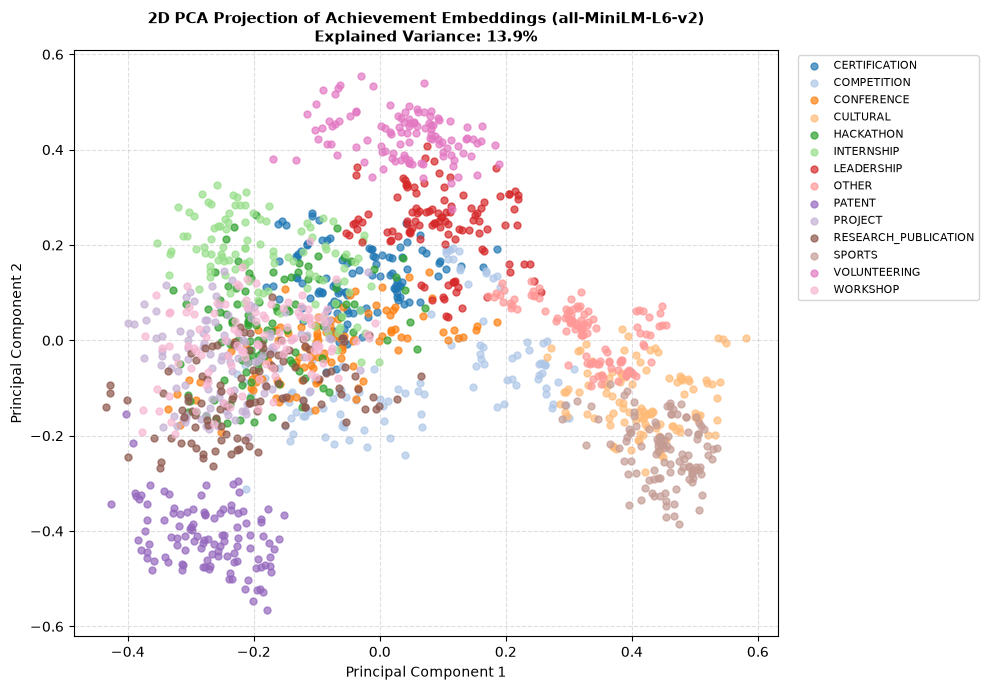

In [7]:
pca = PCA(n_components=2, random_state=42)
embs_2d = pca.fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(10, 7))
unique_cats = sorted(list(set(categories)))
cmap = plt.get_cmap("tab20")

for i, cat in enumerate(unique_cats):
    mask = [c == cat for c in categories]
    ax.scatter(embs_2d[mask, 0], embs_2d[mask, 1], label=cat, alpha=0.7, s=25, color=cmap(i % 20))

ax.set_title(f"2D PCA Projection of Achievement Embeddings (all-MiniLM-L6-v2)\nExplained Variance: {pca.explained_variance_ratio_.sum():.1%}", fontsize=11, fontweight="bold")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

## 8. Summary & Certification
- Generated deterministic, L2-normalized embeddings for all 1,540 achievement records.
- Validated zero NaN/Inf values and exact 384 dimensions.
- Persisted versioned artifacts in `data/embeddings/achievement_dataset_v1.0.1/`.